# Extra EDA for Narrative Analysis Purposes

because we changed all 3 of our research questions I wanted to explore those more in-depth since we haven't really done that yet

In [184]:
import polars as pl
import nflreadpy as nfl
import numpy as np
import matplotlib.pyplot as plt
import pyarrow as pa
import seaborn as sns
import plotly.express as px

pbp = nfl.load_pbp(2025)

# may be useful for 4th downs based on professor feedback to include more years, but i'll put it in
# a separate dataset for now
pbpMultYears = nfl.load_pbp([2021, 2022, 2023, 2024, 2025])

playerStats = nfl.load_player_stats(2025)
ngsRecStats = nfl.load_nextgen_stats(2025, stat_type = "receiving")

# additional dataset for team stats, might be useful might not be idk
teamStats = nfl.load_team_stats(2025, "reg")

In [185]:
# filtering pbp to only include relevant data for our questions
pbp = pbp.select([
    "play_type", "yards_gained", "epa", "success", "down", "ydstogo",
    "yardline_100", "qtr", "posteam", "defteam", "game_id", "week"
])
pbpMultYears = pbpMultYears.select([
    "play_type", "yards_gained", "epa", "success", "down", "ydstogo",
    "yardline_100", "qtr", "posteam", "defteam", "game_id", "week"
])

# only include reg season
pbp = pbp.filter(pl.col("week") <= 17)
pbpMultYears = pbpMultYears.filter(pl.col("week") <= 17)

In [186]:
# filtering ngsStats to further include relevant data for our questions (intended air yardage)
ngsRecStats = ngsRecStats.select(["player_gsis_id",
    "player_display_name",
    "player_position",
    "team_abbr",
    "season",
    "week",
    "avg_cushion",
    "avg_separation",
    "yards",
    "avg_yac",
    "avg_expected_yac",
    "avg_yac_above_expectation",
    "avg_intended_air_yards",])

### Question 1: How do rushing and passing success rates individually correlate with NFL team win percentages?

this already has a graph in the original EDA document
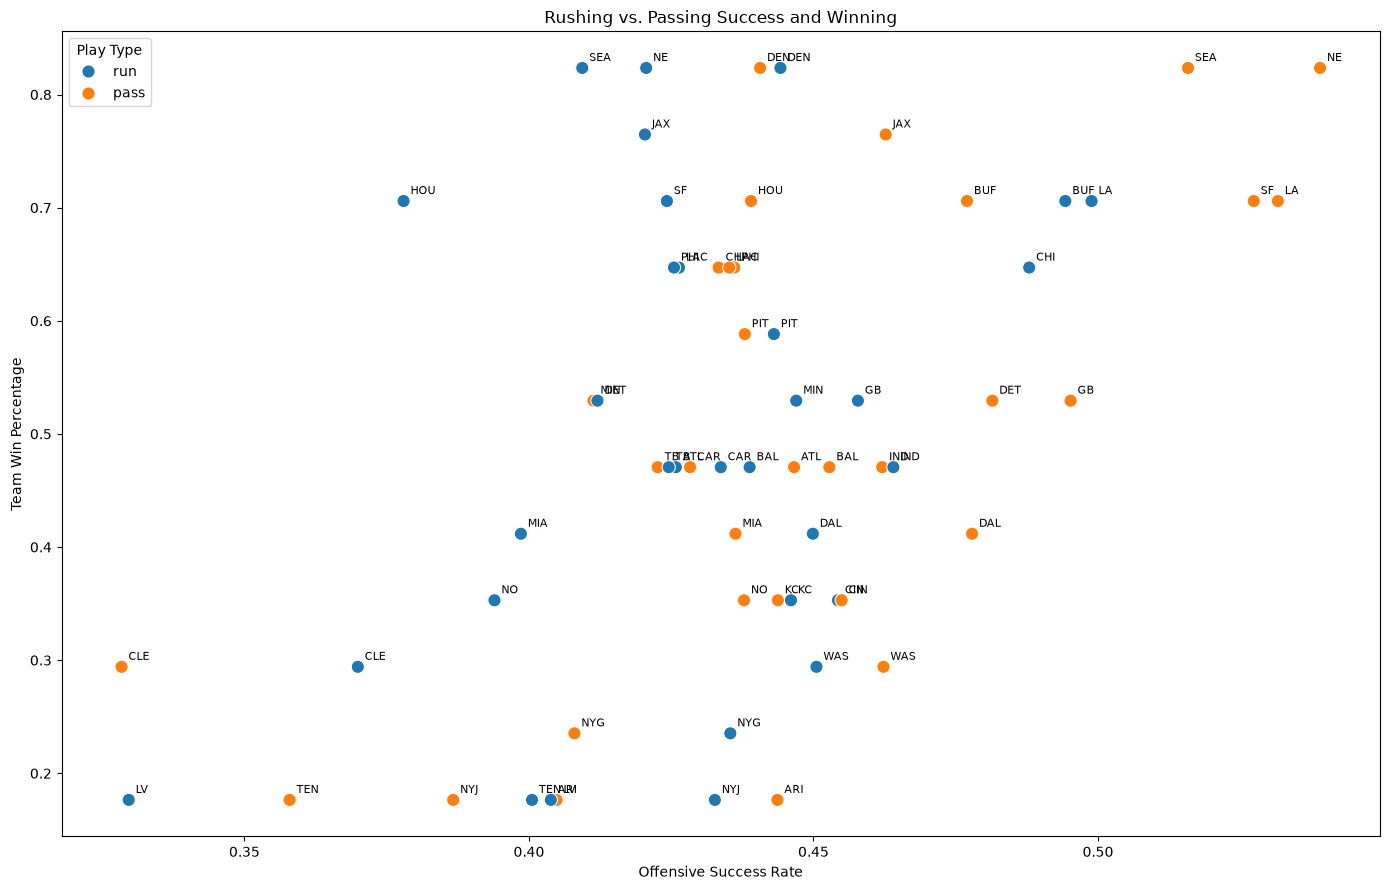

### Question 2: How do yards to go and field position affect the average EPA of punting versus going for it on fourth down?

original EDA document has the 4th down visual but does not include field position in it. the idea here is to try and incorporate how field position changes the rate at which teams go for it or punt, as well as the EPA at each position

In [187]:
# TODO

### Question 3: How does average WR separation correlate with receiving yards per target, and does this relationship change based on route depth?

original EDA document found a pretty inconclusive showing that separation alone is correlated with yards per target, so the idea is to see if depth of target might change this

In [188]:
# calculate yards per target for wrs
recStats = (
    playerStats.select(["player_id",
        "season",
        "week",
        "receiving_yards",
        "targets"
    ])
    .rename({
        "player_id": "player_gsis_id",
        "receiving_yards": "yards",
        "targets": "weekly_targets"
    })
)
recStats = ngsRecStats.join(
    recStats,
    on=["player_gsis_id", "season", "week"],
    how="inner"
)
recStats = recStats.with_columns(
    (pl.col("yards") / pl.col("weekly_targets")).alias("yards_per_target")
)
recStats

player_gsis_id,player_display_name,player_position,team_abbr,season,week,avg_cushion,avg_separation,yards,avg_yac,avg_expected_yac,avg_yac_above_expectation,avg_intended_air_yards,yards_right,weekly_targets,yards_per_target
str,str,str,str,i32,i32,f64,f64,i32,f64,f64,f64,f64,i32,i32,f64
"""00-0030061""","""Zach Ertz""","""TE""","""WAS""",2025,1,6.336,2.454593,26,2.02,1.929988,0.090012,8.252,26,5,5.2
"""00-0030279""","""Keenan Allen""","""WR""","""LAC""",2025,1,5.2,3.497281,68,2.781429,3.122002,-0.340573,8.944,68,10,6.8
"""00-0031381""","""Davante Adams""","""WR""","""LAR""",2025,1,6.7925,1.61925,51,2.545,1.629017,0.915983,8.52875,51,8,6.375
"""00-0031408""","""Mike Evans""","""WR""","""TB""",2025,1,4.985,1.797824,51,0.842,2.138415,-1.296415,13.00375,51,8,6.375
"""00-0031588""","""Stefon Diggs""","""WR""","""NE""",2025,1,3.584,3.373366,57,3.616667,5.465305,-1.848638,7.894286,57,7,8.142857
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""00-0034348""","""Courtland Sutton""","""WR""","""DEN""",2025,21,6.5,2.782492,17,0.283333,0.158608,0.124726,9.318,17,5,3.4
"""00-0038543""","""Jaxon Smith-Njigba""","""WR""","""SEA""",2025,21,4.259,3.29308,153,4.864,3.897939,0.966061,11.451667,153,12,12.75
"""00-0038608""","""Kayshon Boutte""","""WR""","""NE""",2025,21,7.116667,1.507822,6,2.28,1.926855,0.353145,22.04,6,6,1.0


In [189]:
# distribution plots of yards per target and intended air yards
fig = px.box(recStats, x="avg_intended_air_yards")
fig.update_layout(width = 800, height = 600)
fig

In [190]:
# make two separate plots for ypt and separation, grouped by intended air yards.
# split will be at the median of the intended air yards (9.59)
recStatsLowYardage = recStats.filter(pl.col("avg_intended_air_yards") < 9.59)
recStatsHighYardage = recStats.filter(pl.col("avg_intended_air_yards") >= 9.59)

# convert to pandas for seaborn
plot1 = recStatsLowYardage.to_pandas()
plot2 = recStatsHighYardage.to_pandas()

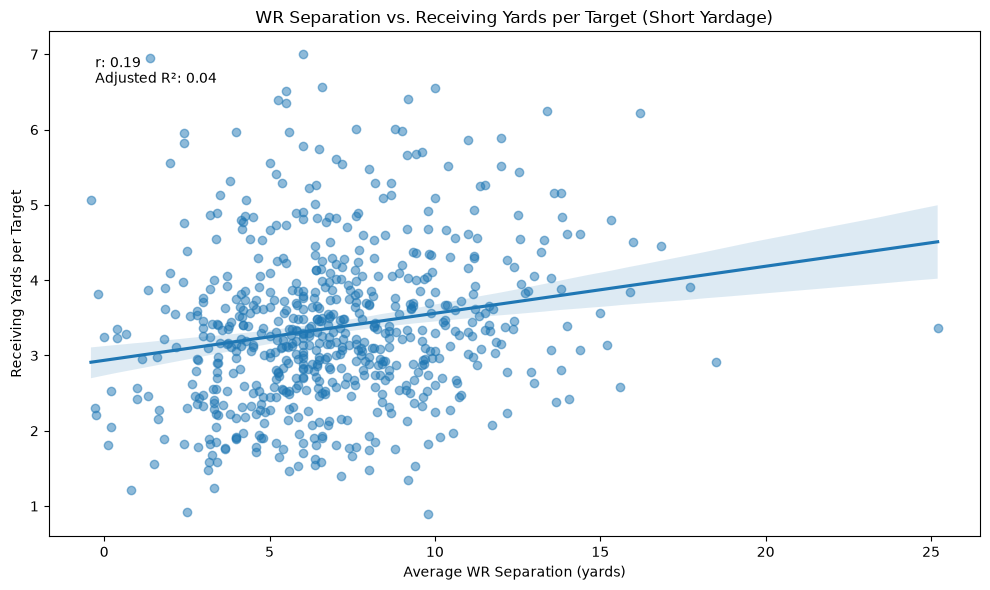

In [191]:
# short yardage depth plot
plt.figure(figsize=(10,6))
sns.regplot(data=plot1,
            x="yards_per_target",
            y="avg_separation",
            scatter_kws = {"alpha": 0.5})

plt.title("WR Separation vs. Receiving Yards per Target (Short Yardage)")
plt.xlabel("Average WR Separation (yards)")
plt.ylabel("Receiving Yards per Target")

# show correlation coefficient on plot
correlation = plot1["yards_per_target"].corr(plot1["avg_separation"])
plt.text(0.05, 0.95, f"r: {correlation:.2f}", transform=plt.gca().transAxes, va="top")

# show adj r^2 on plot data. adjusted r^2 is a measure of how well the regression line fits the data,
# adjusted to take model density into account
adj_r_squared = plot1["yards_per_target"].corr(plot1["avg_separation"]) ** 2
plt.text(0.05, 0.92, f"Adjusted R²: {adj_r_squared:.2f}", transform=plt.gca().transAxes, va="top")

plt.tight_layout()
plt.show()

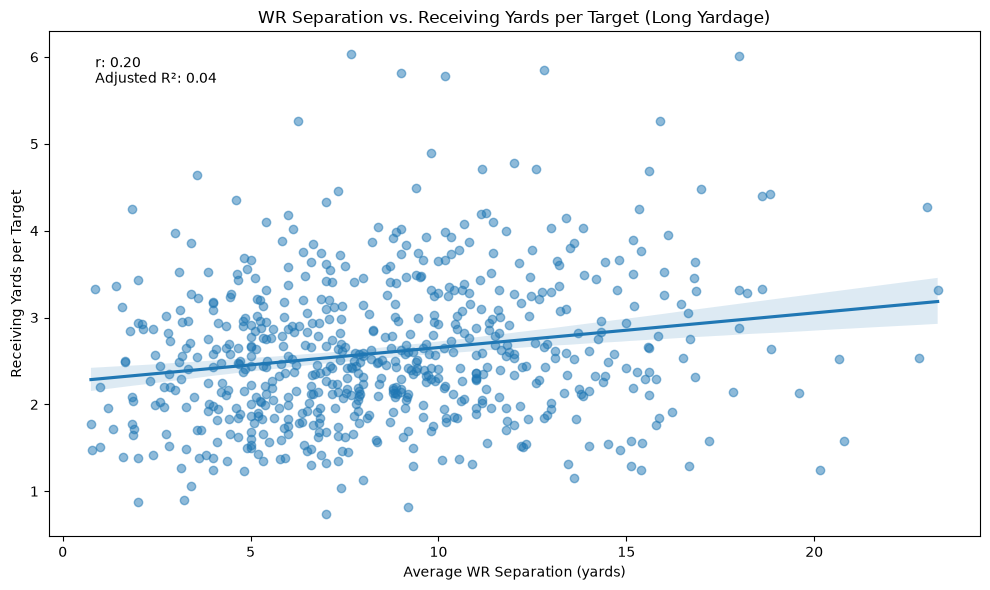

In [192]:
# long yardage depth plot
plt.figure(figsize=(10,6))
sns.regplot(data=plot2,
            x="yards_per_target",
            y="avg_separation",
            scatter_kws = {"alpha": 0.5})

plt.title("WR Separation vs. Receiving Yards per Target (Long Yardage)")
plt.xlabel("Average WR Separation (yards)")
plt.ylabel("Receiving Yards per Target")

# show correlation coefficient on plot
correlation = plot2["yards_per_target"].corr(plot2["avg_separation"])
plt.text(0.05, 0.95, f"r: {correlation:.2f}", transform=plt.gca().transAxes, va="top")

# show adj r^2 on plot
adj_r_squared = plot2["yards_per_target"].corr(plot2["avg_separation"]) ** 2
plt.text(0.05, 0.92, f"Adjusted R²: {adj_r_squared:.2f}", transform=plt.gca().transAxes, va="top")

plt.tight_layout()
plt.show()

Both plots show a similarly weak positive correlation for more separation accounting for more YPT, but the correlation is slightly stronger than it was when unadjusted for air yardage. Interestingly, the intercept is actually around 0.5 yards higher for receivers with lower intended air yards than receivers with higher intended air yards, which could explain the discrepancy. 